# Ranking evaluation and pipeline

Three figures for the report:

1. **Pipeline**: the steps from raw data to results.
2. **Rank change**: ranking by number of postings (baseline) vs. by postings per study place (method).
3. **Robustness**: the method's rank for each programme under five definitions of demand.

Data: `data/eval/ranking_ranks.csv` (from `src/evaluate_ranking.py`). The figures are also saved as PNG in `figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch

ROOT = Path.cwd()
if not (ROOT / "data/eval").exists():
    ROOT = ROOT.parent

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

ranks = pd.read_csv(ROOT / "data/eval/ranking_ranks.csv", index_col="programme")
ranks = ranks.rename(index={"Psykologi (profesjonsstudium)": "Psykologi"})

TOP = "#D97941"    # top 3 (same as notebook 02)
OTHER = "#B8C2CC"  # other programmes
TEXT = "#333333"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### Pipeline

The main pipeline (top row) ranks the programmes. The side branch (bottom row) finds and evaluates the skills employers ask for. Script names are in grey.

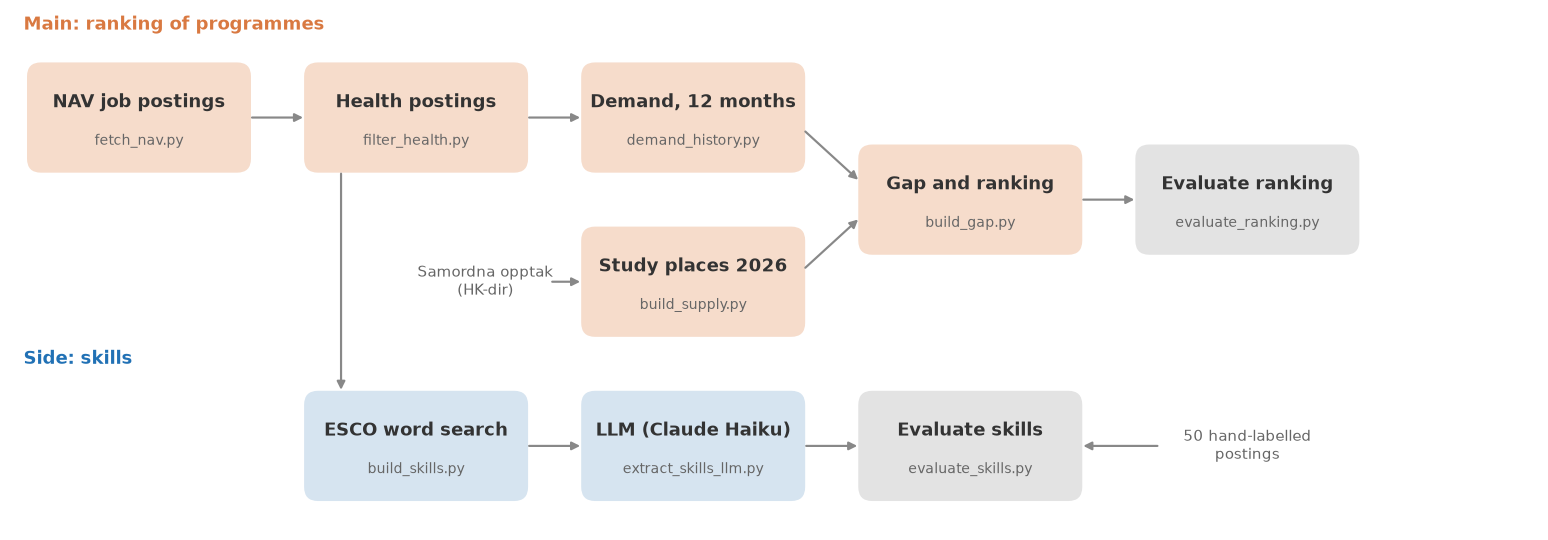

In [2]:
def box(ax, x, y, title, script, color):
    w, h = 1.9, 0.9
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h,
                                boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=color, edgecolor="none"))
    ax.text(x, y + 0.13, title, ha="center", va="center", fontsize=10.5,
            fontweight="bold", color=TEXT)
    ax.text(x, y - 0.2, script, ha="center", va="center", fontsize=8.5, color="#666666")


def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="#888888", lw=1.3))


MAIN = "#F6DCCB"
SIDE = "#D6E4F0"
EVAL = "#E3E3E3"

fig, ax = plt.subplots(figsize=(13, 4.6))
ax.set_xlim(-1.1, 12.1)
ax.set_ylim(-0.1, 4.3)
ax.axis("off")

# Main pipeline: demand + supply -> ranking -> evaluation
box(ax, 0, 3.4, "NAV job postings", "fetch_nav.py", MAIN)
box(ax, 2.4, 3.4, "Health postings", "filter_health.py", MAIN)
box(ax, 4.8, 3.4, "Demand, 12 months", "demand_history.py", MAIN)
box(ax, 4.8, 2.0, "Study places 2026", "build_supply.py", MAIN)
box(ax, 7.2, 2.7, "Gap and ranking", "build_gap.py", MAIN)
box(ax, 9.6, 2.7, "Evaluate ranking", "evaluate_ranking.py", EVAL)
arrow(ax, 0.95, 3.4, 1.45, 3.4)
arrow(ax, 3.35, 3.4, 3.85, 3.4)
arrow(ax, 5.75, 3.3, 6.25, 2.85)
arrow(ax, 5.75, 2.1, 6.25, 2.55)
arrow(ax, 8.15, 2.7, 8.65, 2.7)
ax.text(3.0, 2.0, "Samordna opptak\n(HK-dir)", ha="center", va="center", fontsize=9, color="#666666")
arrow(ax, 3.55, 2.0, 3.85, 2.0)

# Side branch: skills
box(ax, 2.4, 0.6, "ESCO word search", "build_skills.py", SIDE)
box(ax, 4.8, 0.6, "LLM (Claude Haiku)", "extract_skills_llm.py", SIDE)
box(ax, 7.2, 0.6, "Evaluate skills", "evaluate_skills.py", EVAL)
arrow(ax, 1.75, 2.95, 1.75, 1.05)
arrow(ax, 3.35, 0.6, 3.85, 0.6)
arrow(ax, 5.75, 0.6, 6.25, 0.6)
ax.text(9.6, 0.6, "50 hand-labelled\npostings", ha="center", va="center", fontsize=9, color="#666666")
arrow(ax, 8.85, 0.6, 8.15, 0.6)

ax.text(-1.0, 4.15, "Main: ranking of programmes", fontsize=11, color=TOP, fontweight="bold")
ax.text(-1.0, 1.3, "Side: skills", fontsize=11, color="#2171B5", fontweight="bold")

fig.tight_layout()
fig.savefig(FIGURES / "pipeline.png", bbox_inches="tight", dpi=200)
plt.show()

### Rank change: number of postings vs. postings per study place

Left: rank when we only count postings (baseline). Right: rank by postings per study place (our method). Orange lines are the method's top 3. Sykepleie and Vernepleie fall because they are large programmes; Odontologi rises from 8th to 3rd place. Spearman correlation between the two rankings is 0.74, and only Medisin is in both top 3 lists.

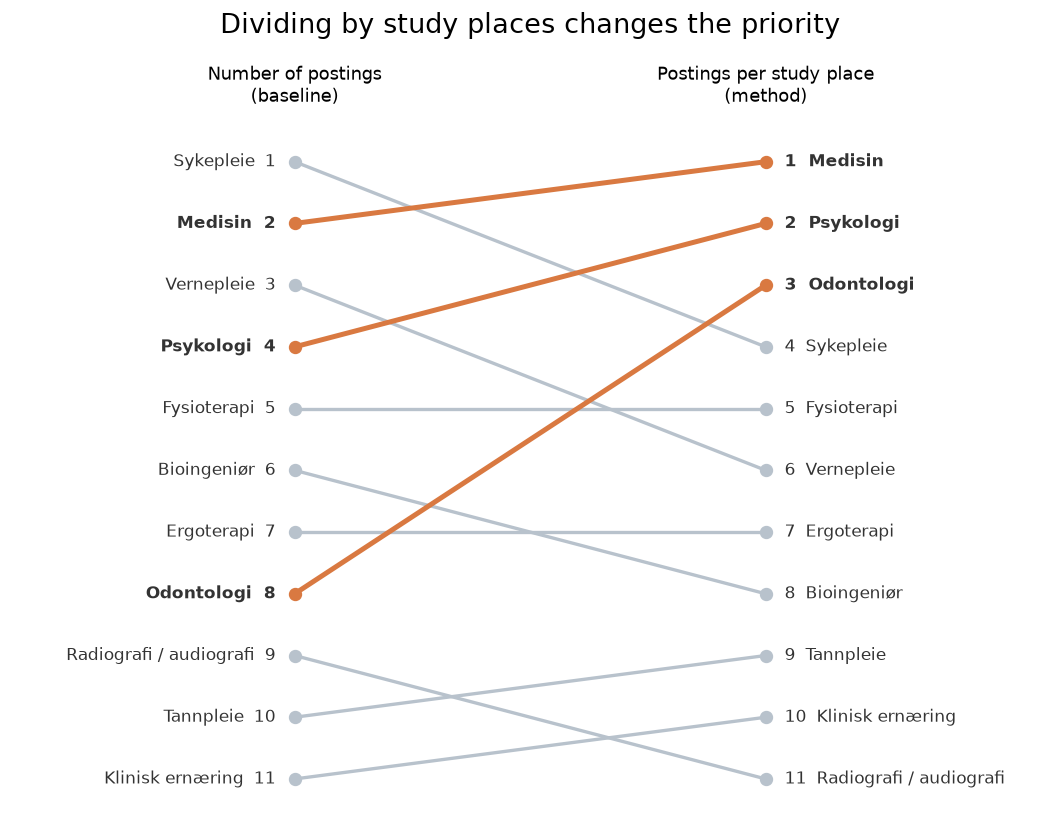

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))

for programme, row in ranks.iterrows():
    left, right = int(row["rank_baseline"]), int(row["rank_method"])
    top = right <= 3
    color = TOP if top else OTHER
    weight = "bold" if top else "normal"
    ax.plot([0, 1], [left, right], color=color, lw=3 if top else 2, marker="o", markersize=7,
            zorder=3 if top else 2)
    ax.text(-0.04, left, f"{programme}  {left}", ha="right", va="center",
            fontsize=10, color=TEXT, fontweight=weight)
    ax.text(1.04, right, f"{right}  {programme}", ha="left", va="center",
            fontsize=10, color=TEXT, fontweight=weight)

ax.set_xlim(-0.6, 1.6)
ax.set_ylim(len(ranks) + 0.6, 0.4)
ax.set_xticks([0, 1], ["Number of postings\n(baseline)", "Postings per study place\n(method)"],
              fontsize=11)
ax.tick_params(axis="x", length=0, pad=10)
ax.set_yticks([])
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.xaxis.set_ticks_position("top")
ax.set_title("Dividing by study places changes the priority", fontsize=16, pad=55)

fig.tight_layout()
fig.savefig(FIGURES / "rank_change.png", bbox_inches="tight", dpi=200)
plt.show()